In [1]:
import json
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols` package (and this notebook's other modules) is in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk, gradient_check
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import reset_trainable, snapshot_trainable
from beta_train.reports import best_beta_table, best_table, comparison_table, eval_beta_table, mse_decomposition, per_dataset_table
from beta_train.runs import load_best
from beta_train.trainer import RunResult, load_run, run_training
from beta_train.validation import PopulationValidator, TrainingPathValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to run jaredpalmer/kev-0.8b in bf16 train mode")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
model_load_sec,1.649


Snapshotted 376 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Datasets this notebook uses; only these are loaded (the others are skipped to save time)
ITEM_DATASETS = [         # training items are built for these (training, gradient check, VRAM search)
    "wu2025",
    "berke2023",
]
VALIDATION_DATASETS = [   # validation runs on these: the training datasets themselves (in-sample population betas)
    "wu2025",
    "berke2023",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Validation uses the whole dataset. Training splits a dataset with several task variables (`v`) into one pseudo
# dataset per task ("<dataset>/<v>"), so an item holds one respondent's tasks of a single kind.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")


wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

berke2023: 3,625 respondents | 36,297 tasks | 4 regression(s)


berke2023/v0                  berke2023/v1                  berke2023/v2                  berke2023/v3                 
                                           beta      se std_beta         beta      se std_beta         beta      se std_beta         beta      se std_beta
Drone privacy: YES vs NO                 0.1607  0.0095   0.3214       0.2242  0.0088   0.4484       0.2107  0.0111   0.4215       0.2138  0.0102   0.4277
Fee L1 vs $0 ($1)                       -0.1509  0.0088  -0.3018      -0.0822  0.0087  -0.1644      -0.1534  0.0114  -0.3068      -0.1659  0.0117  -0.3318
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3298  0.0102  -0.6595      -0.2964  0.0096  -0.5929      -0.3251  0.0128  -0.6503      -0.3608  0.0123  -0.7216
Fee L3 vs $0 ($5 fast / $10 meds)       -0.4978  0.0108  -0.9956      -0.5023  0.0108  -1.0045      -0.5268  0.0126  -1.0537      -0.5790  0.0145  -1.1580
Wait L1 vs L0 (20m fast / 2h meds)      -0.0631  0.0107  -0.1261      -0.0743  0.0095  -0.1487      -0.0242  0.0109  -0.0484      -0.0709  0.0099  -0.1417
Wait L2 vs L0 (30m fast / 6h meds)      -0.2082  0.0106  -0.4164      -0.1924  0.0095  -0.3848      -0.1521  0.0111  -0.3043      -0.2184  0.0115  -0.4369
Wait L3 vs L0 (45m fast / 1d meds)      -0.3419  0.0124  -0.6837      -0.2638  0.0102  -0.5276      -0.2772  0.0130  -0.5545      -0.3460  0.0135  -0.6919
sigma_y                                  0.5000     NaN      NaN       0.5000     NaN      NaN       0.5000     NaN      NaN       0.5000     NaN      NaN
n_rows                               19056.0000     NaN      NaN   22962.0000     NaN      NaN   14538.0000     NaN      NaN   16038.0000     NaN      NaN

berke2023/delivery_choice_v0: 3,014 respondents | 9,528 tasks | 1 regression(s)


berke2023/v0                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.1607  0.0095   0.3214
Fee L1 vs $0 ($1)                       -0.1509  0.0088  -0.3018
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3298  0.0102  -0.6595
Fee L3 vs $0 ($5 fast / $10 meds)       -0.4978  0.0108  -0.9956
Wait L1 vs L0 (20m fast / 2h meds)      -0.0631  0.0107  -0.1261
Wait L2 vs L0 (30m fast / 6h meds)      -0.2082  0.0106  -0.4164
Wait L3 vs L0 (45m fast / 1d meds)      -0.3419  0.0124  -0.6837
sigma_y                                  0.5000     NaN      NaN
n_rows                               19056.0000     NaN      NaN

... (3 outputs left out)

berke2023/v2                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2107  0.0111   0.4215
Fee L1 vs $0 ($1)                       -0.1534  0.0114  -0.3068
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3251  0.0128  -0.6503
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5268  0.0126  -1.0537
Wait L1 vs L0 (20m fast / 2h meds)      -0.0242  0.0109  -0.0484
Wait L2 vs L0 (30m fast / 6h meds)      -0.1521  0.0111  -0.3043
Wait L3 vs L0 (45m fast / 1d meds)      -0.2772  0.0130  -0.5545
sigma_y                                  0.5000     NaN      NaN
n_rows                               14538.0000     NaN      NaN

berke2023/delivery_choice_v3: 2,577 respondents | 8,019 tasks | 1 regression(s)


berke2023/v3                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2138  0.0102   0.4277
Fee L1 vs $0 ($1)                       -0.1659  0.0117  -0.3318
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3608  0.0123  -0.7216
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5790  0.0145  -1.1580
Wait L1 vs L0 (20m fast / 2h meds)      -0.0709  0.0099  -0.1417
Wait L2 vs L0 (30m fast / 6h meds)      -0.2184  0.0115  -0.4369
Wait L3 vs L0 (45m fast / 1d meds)      -0.3460  0.0135  -0.6919
sigma_y                                  0.5000     NaN      NaN
n_rows                               16038.0000     NaN      NaN

TRAIN_DATASETS = ['wu2025', 'berke2023/delivery_choice_v0', 'berke2023/delivery_choice_v1', 'berke2023/delivery_choice_v2', 'berke2023/delivery_choice_v3']


# Model, validators, and training items

In [4]:
# One validator per VALIDATION_DATASETS entry (population OLS from the dataset's module); pick how inference runs
VALIDATOR_KIND = "fused"   # "fused": LoRA merged + fused kernels + CUDA graphs, persona states shared
                           # "training_path": the training forward in eval mode, LoRA unmerged (no merge/offload/capture)
# "fused" per-GPU-batch inference budgets: lower them if validation runs out of memory (bigger models), raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
# "training_path" items (data rows) per forward pass (no gradients, so far above the training micro-chunk)
VALIDATION_EVAL_CHUNK = 32

validators = {}
if VALIDATOR_KIND == "fused":
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = PopulationValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            max_questions=VALIDATION_MAX_QUESTIONS,
            max_chars=VALIDATION_MAX_CHARS,
        )
elif VALIDATOR_KIND == "training_path":
    # The training path runs on items (tokenized respondents), cached on disk like the training items
    validation_modules = {}
    for dataset_name in VALIDATION_DATASETS:
        validation_modules[dataset_name] = beta_ols.DATASET_MODULES[dataset_name]
    validation_items, validation_items_report = build_items_cached(kev_model, validation_modules, choice_dfs, cache_dir=CACHE_DIR)
    display(validation_items_report)
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = TrainingPathValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            validation_items[dataset_name],
            eval_chunk=VALIDATION_EVAL_CHUNK,
        )
else:
    raise ValueError(f"VALIDATOR_KIND must be 'fused' or 'training_path', got {VALIDATOR_KIND!r}")
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,prep_sec
validator,,,,,,,
wu2025,fused,18591,1831,wu2025,1024,1000000,2.788
berke2023,fused,36297,1881,"berke2023/v0, berke2023/v1, berke2023/v2, berk...",1024,1000000,4.313


In [5]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

Tokenizing wu2025_validation:   0%|          | 0/1831 [00:00<?, ?state/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Tokenizing berke2023_validation:   0%|          | 0/1881 [00:00<?, ?state/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

,source
validator,
wu2025,computed
berke2023,computed


,wu2025,berke2023
kl_loss,1.0700,0.8187
beta_mse,0.0512,0.1186
beta_mae,0.2093,0.2971
beta_mape_pct,114.1426,123.8190
spearman_rho,-0.2143,-0.3410
eval_prep_sec,3.4127,13.8538
eval_gpu_sec,30.8594,122.7065
eval_wall_sec,36.6694,138.3886
eval_ms_per_task,1.9724,3.8127


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Monthly bill: $110 vs $105,wu2025,-0.0969,-0.0068,0.0901,0.0901
Monthly bill: $115 vs $105,wu2025,-0.1779,-0.0121,0.1659,0.1659
Monthly bill: $120 vs $105,wu2025,-0.2894,-0.0171,0.2723,0.2723
Monthly bill: $125 vs $105,wu2025,-0.3832,-0.0247,0.3584,0.3584
Percentage of renewables: 30% vs 10%,wu2025,0.0973,-0.0075,-0.1048,0.1048
Percentage of renewables: 50% vs 10%,wu2025,0.1706,-0.0150,-0.1856,0.1856
Percentage of renewables: 100% vs 10%,wu2025,0.2421,-0.0399,-0.2820,0.2820
Locally produced renewables: Yes vs No,wu2025,0.1042,-0.1109,-0.2151,0.2151


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
v0: take-out food | Drone privacy: YES vs NO,berke2023/v0,0.1607,-0.2362,-0.3969,0.3969
v0: take-out food | Fee L1 vs $0 ($1),berke2023/v0,-0.1509,-0.0218,0.1291,0.1291
v0: take-out food | Fee L2 vs $0 ($3 fast / $5 meds),berke2023/v0,-0.3298,-0.0141,0.3156,0.3156
v0: take-out food | Fee L3 vs $0 ($5 fast / $10 meds),berke2023/v0,-0.4978,0.0002,0.4980,0.4980
v0: take-out food | Wait L1 vs L0 (20m fast / 2h meds),berke2023/v0,-0.0631,0.0024,0.0654,0.0654
v0: take-out food | Wait L2 vs L0 (30m fast / 6h meds),berke2023/v0,-0.2082,0.0211,0.2293,0.2293
v0: take-out food | Wait L3 vs L0 (45m fast / 1d meds),berke2023/v0,-0.3419,0.0371,0.3790,0.3790
v1: prescription medications | Drone privacy: YES vs NO,berke2023/v1,0.2242,-0.3136,-0.5378,0.5378
v1: prescription medications | Fee L1 vs $0 ($1),berke2023/v1,-0.0822,-0.0243,0.0579,0.0579


In [6]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were already
# built for this data, tokenizer, and code; Kev's prepared targets are checked against each respondent's beta part

item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
wu2025,18591,cache
berke2023/delivery_choice_v0,9528,cache
berke2023/delivery_choice_v1,11481,cache
berke2023/delivery_choice_v2,7269,cache
berke2023/delivery_choice_v3,8019,cache


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025
berke2023/delivery_choice_v0,9528,3014,berke2023/v0
berke2023/delivery_choice_v1,11481,3323,berke2023/v1
berke2023/delivery_choice_v2,7269,2381,berke2023/v2
berke2023/delivery_choice_v3,8019,2577,berke2023/v3


# Find max micro chunk

In [ ]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) chunks of these datasets
SEARCH_GRADIENT_CHECKPOINTING = False   # search with the setting you will train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

# Train

In [7]:
# Smaller of the two single-dataset searches (Berke 18, Wu 26), so the worst-case chunk of either dataset fits
MAX_FITTING_MICRO_CHUNK = 16
SEARCH_GRADIENT_CHECKPOINTING = False

In [8]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v10-wu-berke-lambda-dose-800m"
RUNS_DIR = EXPLORATION_DIR / "runs" / NOTEBOOK
# Question of this notebook: does a larger beta_lambda lower the beta MSE on the training datasets themselves (Wu and
# Berke, whole data)? Both validators are in-sample; the dose-response cell below reads every validation, so best.pt
# only matters for later use. ONE validator's column picks it: Wu's beta MSE (lambda-free, so the same rule for all runs).
BEST_METRIC = "wu2025/beta_mse"
BEST_MODE = "min"

# Base run settings; each run cell below sets the sample size (tasks = training items per step, the same for every
# training dataset; with it, the peak LR and the validation steps) and beta_lambda. Training datasets keep their
# natural mix: each contributes ceil(its tasks / S) samples per epoch.
BETA_LAMBDA = 1.0
NUM_EPOCHS = 1
# Peak LR = BASE_LR_PER_TASK x sqrt(sample size in tasks = training items per step), for any mix of training datasets.
# The base is v4's 2e-5 per respondent converted to tasks: v4's items were whole Wu respondents (10 tasks each), so
# 2e-5 x sqrt(S / 10) = (2e-5 / sqrt(10)) x sqrt(S); S = 160 tasks = v4's S = 16 respondents at LR 8e-5
BASE_LR_PER_TASK = 2e-5 / math.sqrt(10)
# Rows (training items) seen between validations, per validator (all validators also run at step 0 and the last step).
# At S = 160: Wu every 20 steps (18,591 short tasks, picks best.pt), Berke every 40 steps (36,297 longer tasks, slower)
EVAL_EVERY_ROWS_BY_VALIDATOR = {"wu2025": 3200, "berke2023": 6400}
# S = 40 tasks per step
BASE_SAMPLE_SIZE = 40
# Debugging: split every step's gradient into its CE and lambda x beta parts and log their norms (steps.csv, live plot).
# Costs one extra pass 2 per step (roughly 1.5x step time)
GRADIENT_SPLIT = True
BASE_CONFIG = TrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={ts: BASE_SAMPLE_SIZE for ts in TRAIN_DATASETS},
    beta_lambda=BETA_LAMBDA,
    lr=scale_lr_for_sample_size(BASE_LR_PER_TASK, BASE_SAMPLE_SIZE),
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator={"wu2025": 20, "berke2023": 40},
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
    gradient_split=GRADIENT_SPLIT,
)


In [9]:
def make_run_config(sample_size: int, beta_lambda: float) -> TrainConfig:
    # BASE_CONFIG with this beta_lambda, this sample size for every training dataset, its sqrt-scaled peak LR, and
    # validation steps = rows between validations / S
    lr = scale_lr_for_sample_size(BASE_LR_PER_TASK, sample_size)
    eval_every_by_validator = {}
    for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
        eval_every_by_validator[validator_name] = max(1, round(eval_every_rows / sample_size))
    sample_size_by_dataset = {}
    for dataset_name in TRAIN_DATASETS:
        sample_size_by_dataset[dataset_name] = sample_size
    return replace(
        BASE_CONFIG,
        beta_lambda=beta_lambda,
        sample_size_by_dataset=sample_size_by_dataset,
        lr=lr,
        eval_every_by_validator=eval_every_by_validator,
    )


def run_name(config: TrainConfig) -> str:
    # Run folder name from the settings this notebook varies: lambda, peak LR, sample size (rows per step), epochs
    sample_sizes = sorted(set(config.as_dict()["sample_size_by_dataset"].values()))
    sample_size_text = "-".join(str(size) for size in sample_sizes)
    return f"lambda={config.beta_lambda:g}_lr={config.lr:g}_S={sample_size_text}_ep={config.num_epochs}"

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": VALIDATOR_KIND,
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

,base_config
train_datasets,"[wu2025, berke2023/delivery_choice_v0, berke20..."
sample_size_by_dataset,"{'wu2025': 40, 'berke2023/delivery_choice_v0':..."
beta_lambda,1.0
lr,0.00004
num_epochs,1
eval_every_by_validator,"{'wu2025': 20, 'berke2023': 40}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,16
gradient_checkpointing,False


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,berke2023/val_loss,berke2023/std_beta_mse,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,lr,wu2025/eval_wall_sec,berke2023/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.06998,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,0.81868,0.47429,0.81868,0.11857,0.29709,123.81899,-0.34100,NaN,36.66939,138.38858,0.00000,NaN,NaN,NaN,NaN,NaN
80,1,3200,0.63816,0.59123,0.01165,0.59123,0.00291,0.04801,28.56678,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,35.05733,NaN,140.53274,10.60855,8.37731,0.00000,10.60855,NaN
160,1,6400,0.57060,0.57559,0.02171,0.57559,0.00543,0.05967,29.42354,0.97619,0.53239,0.01485,0.53239,0.00371,0.04771,25.85529,0.94964,0.00004,35.09838,126.61966,280.34669,2.60634,2.58853,0.00000,2.60634,NaN
240,1,9600,0.53737,0.55879,0.00674,0.55879,0.00168,0.03586,21.31713,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,35.00592,NaN,420.18818,1.70045,1.73640,0.00000,1.70045,NaN
320,1,12800,0.55602,0.55580,0.01172,0.55580,0.00293,0.04469,22.39637,0.97619,0.52622,0.00999,0.52622,0.00250,0.03958,19.77356,0.97646,0.00004,34.93769,126.82835,556.49227,1.64846,1.39185,0.00000,1.64846,NaN
400,1,16000,0.53212,0.54862,0.00605,0.54862,0.00151,0.03374,19.04015,1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,34.88315,NaN,699.09439,1.37375,1.23286,0.00000,1.37375,NaN
480,1,19179,0.54684,0.54508,0.00302,0.54508,0.00075,0.01802,10.91257,1.00000,0.52276,0.00519,0.52276,0.00130,0.02892,17.25522,0.97975,0.00003,34.92405,126.62408,837.69787,1.16715,1.04755,0.00000,1.16715,NaN
560,1,22379,0.53389,0.55479,0.02014,0.55479,0.00504,0.06637,35.91400,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,35.06507,NaN,982.32466,1.10334,1.12780,0.00000,1.10334,NaN
640,1,25540,0.53447,0.52650,0.00159,0.52650,0.00040,0.01643,9.24556,1.00000,0.53936,0.01624,0.53936,0.00406,0.05031,26.78874,0.97646,0.00003,35.03237,126.77448,1122.85703,1.10688,1.03133,0.00000,1.10688,NaN


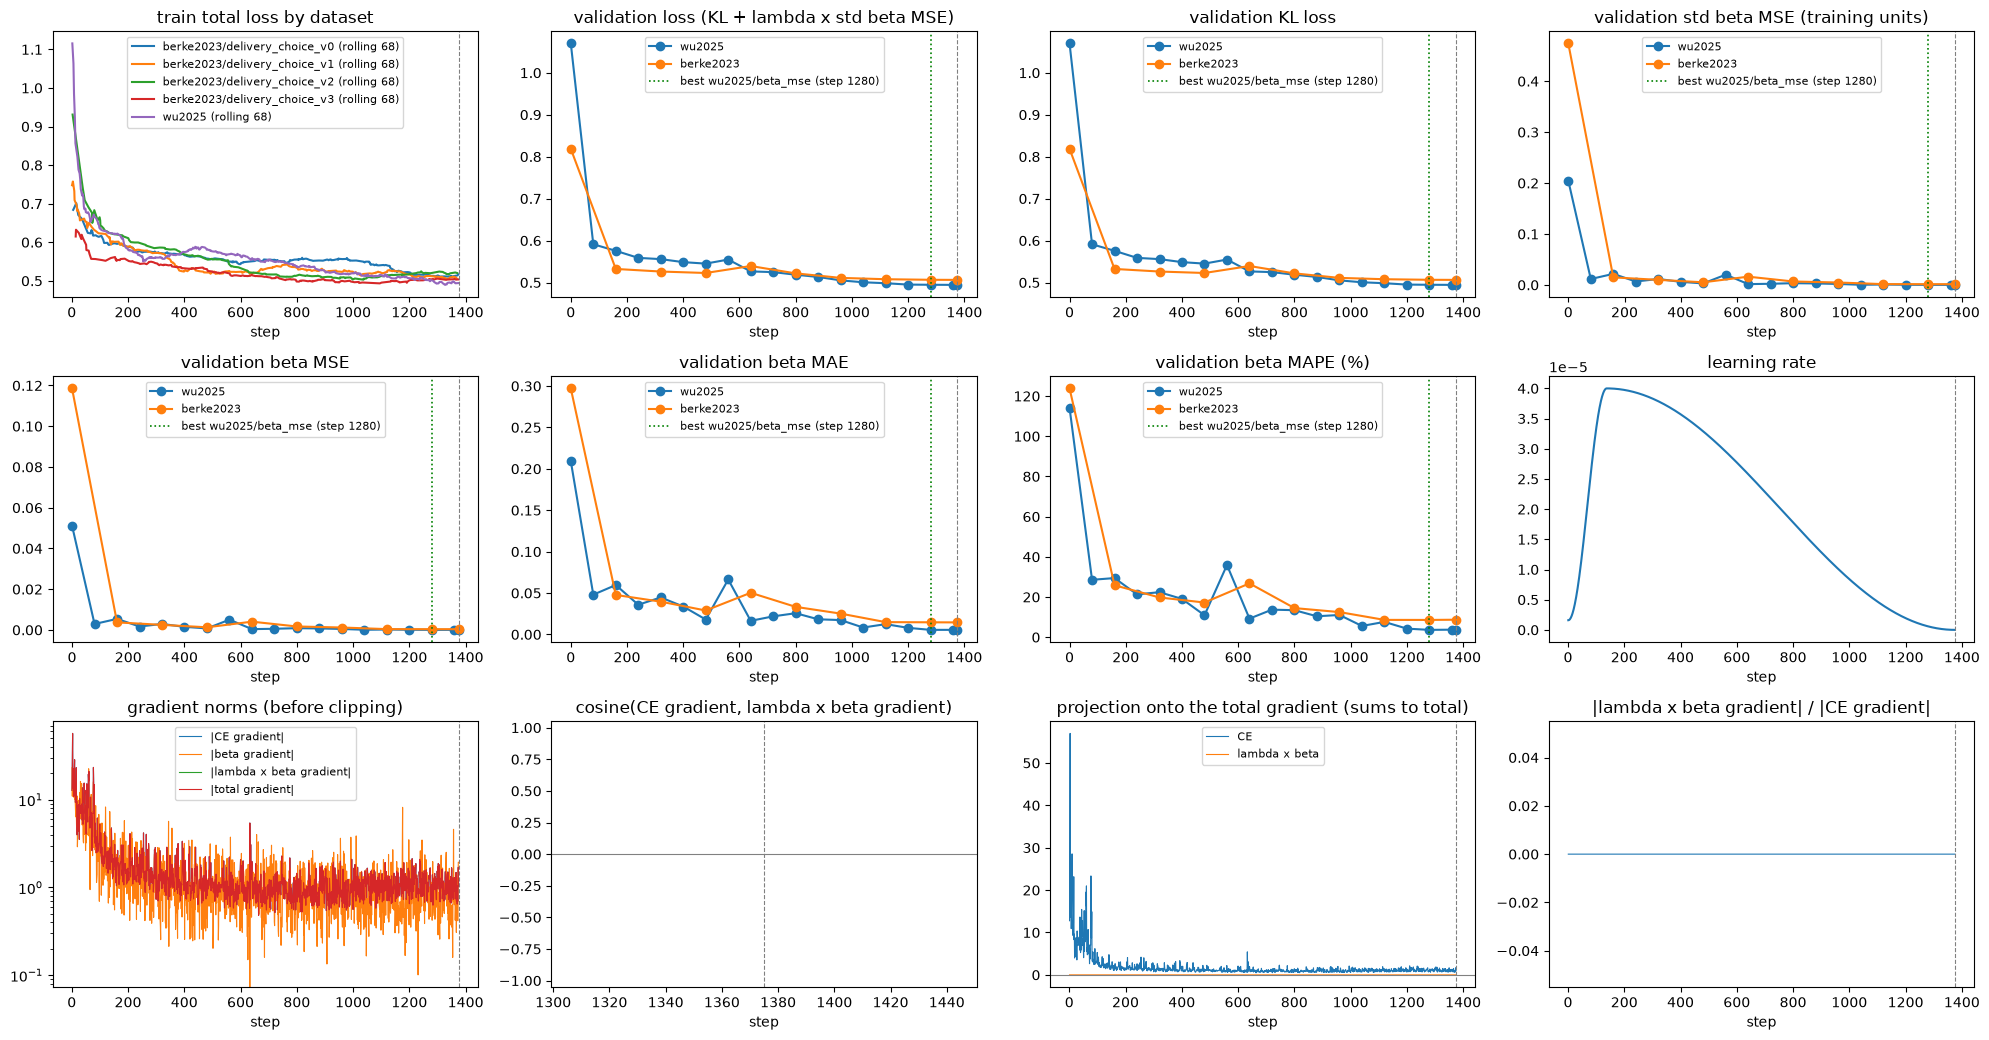

wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delive…

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 03:39:29.059616395 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 91619328, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

... (26 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 04:43:51.411004871 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 95813632, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

In [13]:
sample_size = 40
beta_lambda = 0.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,berke2023/val_loss,berke2023/std_beta_mse,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,lr,wu2025/eval_wall_sec,berke2023/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.27472,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,1.29297,0.47429,0.81868,0.11857,0.29709,123.81899,-0.34100,NaN,36.66939,138.38858,0.00000,NaN,NaN,NaN,NaN,NaN
20,1,3200,0.89675,0.72872,0.09168,0.63704,0.02292,0.13435,68.48775,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00005,36.00867,NaN,137.26717,12.93247,7.98544,7.98544,18.84985,0.54884
40,1,6309,0.67364,0.61684,0.01301,0.60383,0.00325,0.04403,26.06762,0.97619,0.62711,0.05370,0.57341,0.01343,0.09318,41.73475,0.85222,0.00008,35.82151,127.21958,280.51658,3.45833,2.93256,2.93256,5.71043,0.56357
60,1,9509,0.64058,0.62183,0.01759,0.60424,0.00440,0.05429,26.73448,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00008,35.35388,NaN,411.12313,1.86986,1.02809,1.02809,2.61747,0.49077
80,1,12709,0.63326,0.55328,0.00299,0.55030,0.00075,0.02168,10.42477,0.97619,0.59223,0.02969,0.56254,0.00742,0.06730,35.75723,0.90421,0.00008,35.43437,127.29800,548.85976,1.40586,0.93821,0.93821,2.13217,0.54225
100,1,15909,0.60093,0.55643,0.00446,0.55197,0.00111,0.02720,13.86900,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00007,35.59678,NaN,686.53071,0.87538,0.68696,0.68696,1.34741,0.45391


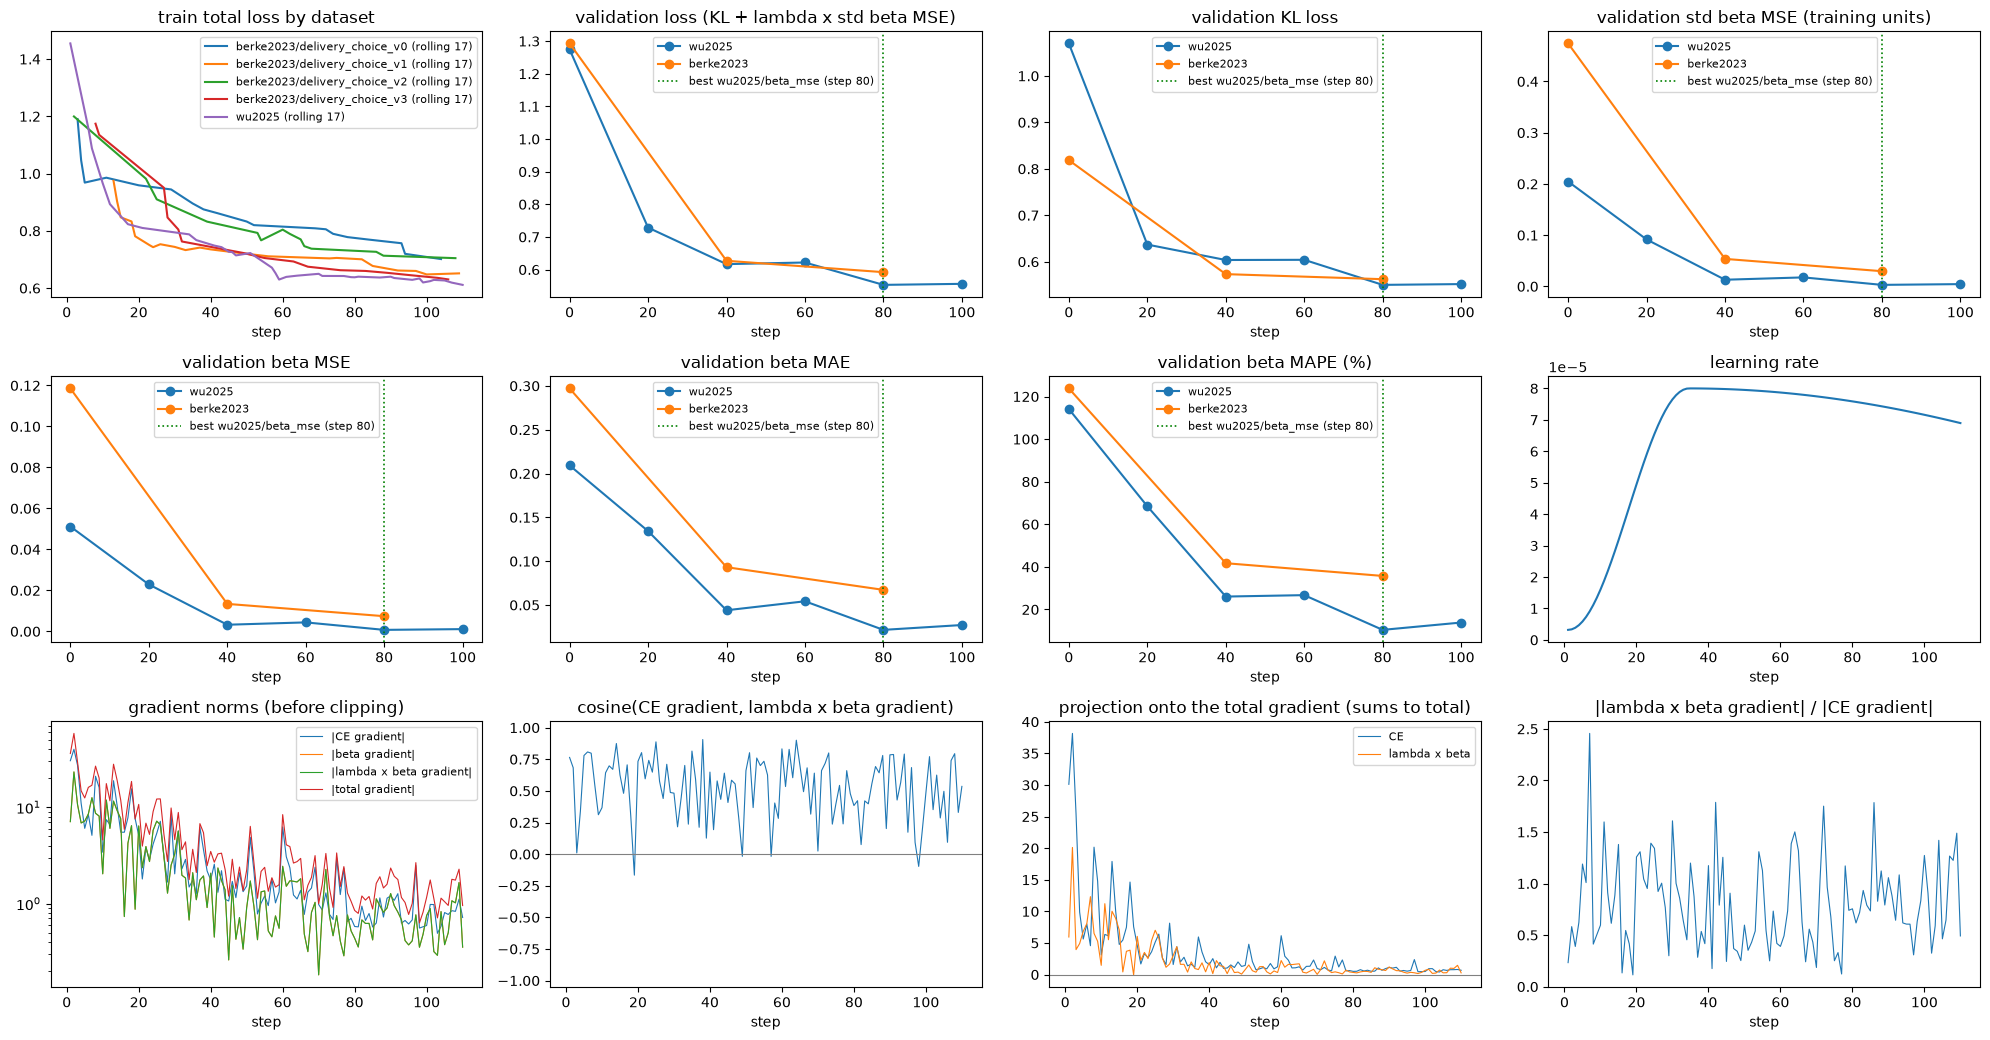

wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delive…

pass 1 (forward): 0it [00:00, ?it/s]

[W1117 08:01:53.640579825 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 5636096, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 08:05:17.755479813 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 70647808, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

... (6 outputs left out)

[W1117 08:17:49.667573554 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 72744960, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 08:20:43.096542950 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 102105088, total: 33733804032).


KeyboardInterrupt: 

In [19]:
sample_size = 160
beta_lambda = 1.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
sample_size = 160
beta_lambda = 0.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,berke2023/val_loss,berke2023/std_beta_mse,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,lr,wu2025/eval_wall_sec,berke2023/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.27472,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,1.29297,0.47429,0.81868,0.11857,0.29709,123.81899,-0.34100,NaN,36.66939,138.38858,0.00000,NaN,NaN,NaN,NaN,NaN
80,1,3200,0.82202,0.57846,0.00440,0.57406,0.00110,0.02651,17.34629,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,36.05053,NaN,142.25171,11.10956,8.92286,8.92286,17.81812,0.52531
160,1,6400,0.71194,0.58238,0.01739,0.56499,0.00435,0.05546,27.38713,1.00000,0.61531,0.03977,0.57554,0.00994,0.08541,39.73641,0.89436,0.00004,35.93224,127.68814,282.77117,3.14904,2.71612,2.71612,5.13805,0.49630
240,1,9600,0.67844,0.57505,0.01009,0.56496,0.00252,0.04683,26.18539,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,35.54716,NaN,423.00755,1.72034,1.61933,1.61933,2.92002,0.46075
320,1,12800,0.67903,0.57403,0.01325,0.56077,0.00331,0.04433,24.83735,0.97619,0.53719,0.01129,0.52591,0.00282,0.04282,22.20221,0.97209,0.00004,35.72111,127.43858,559.89505,1.50932,1.24005,1.24005,2.40582,0.46451
400,1,16000,0.66053,0.56930,0.01110,0.55820,0.00277,0.04575,25.11456,1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,35.59079,NaN,702.97402,1.33671,1.18372,1.18372,2.21231,0.47675
480,1,19179,0.67923,0.55348,0.00099,0.55249,0.00025,0.01372,7.32839,1.00000,0.53913,0.00647,0.53266,0.00162,0.03163,15.75592,0.98084,0.00003,35.38302,126.73634,841.88298,1.15485,1.00233,1.00233,1.93765,0.52539
560,1,22379,0.67173,0.59437,0.02512,0.56925,0.00628,0.06879,34.04756,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,35.15476,NaN,986.60093,1.10326,1.07694,1.07694,1.89778,0.46534
640,1,25540,0.67162,0.55444,0.00631,0.54813,0.00158,0.03663,20.60129,1.00000,0.52950,0.00818,0.52132,0.00205,0.03850,23.67286,0.97701,0.00003,34.94956,126.81730,1127.13879,1.06266,0.94756,0.94756,1.76500,0.46743


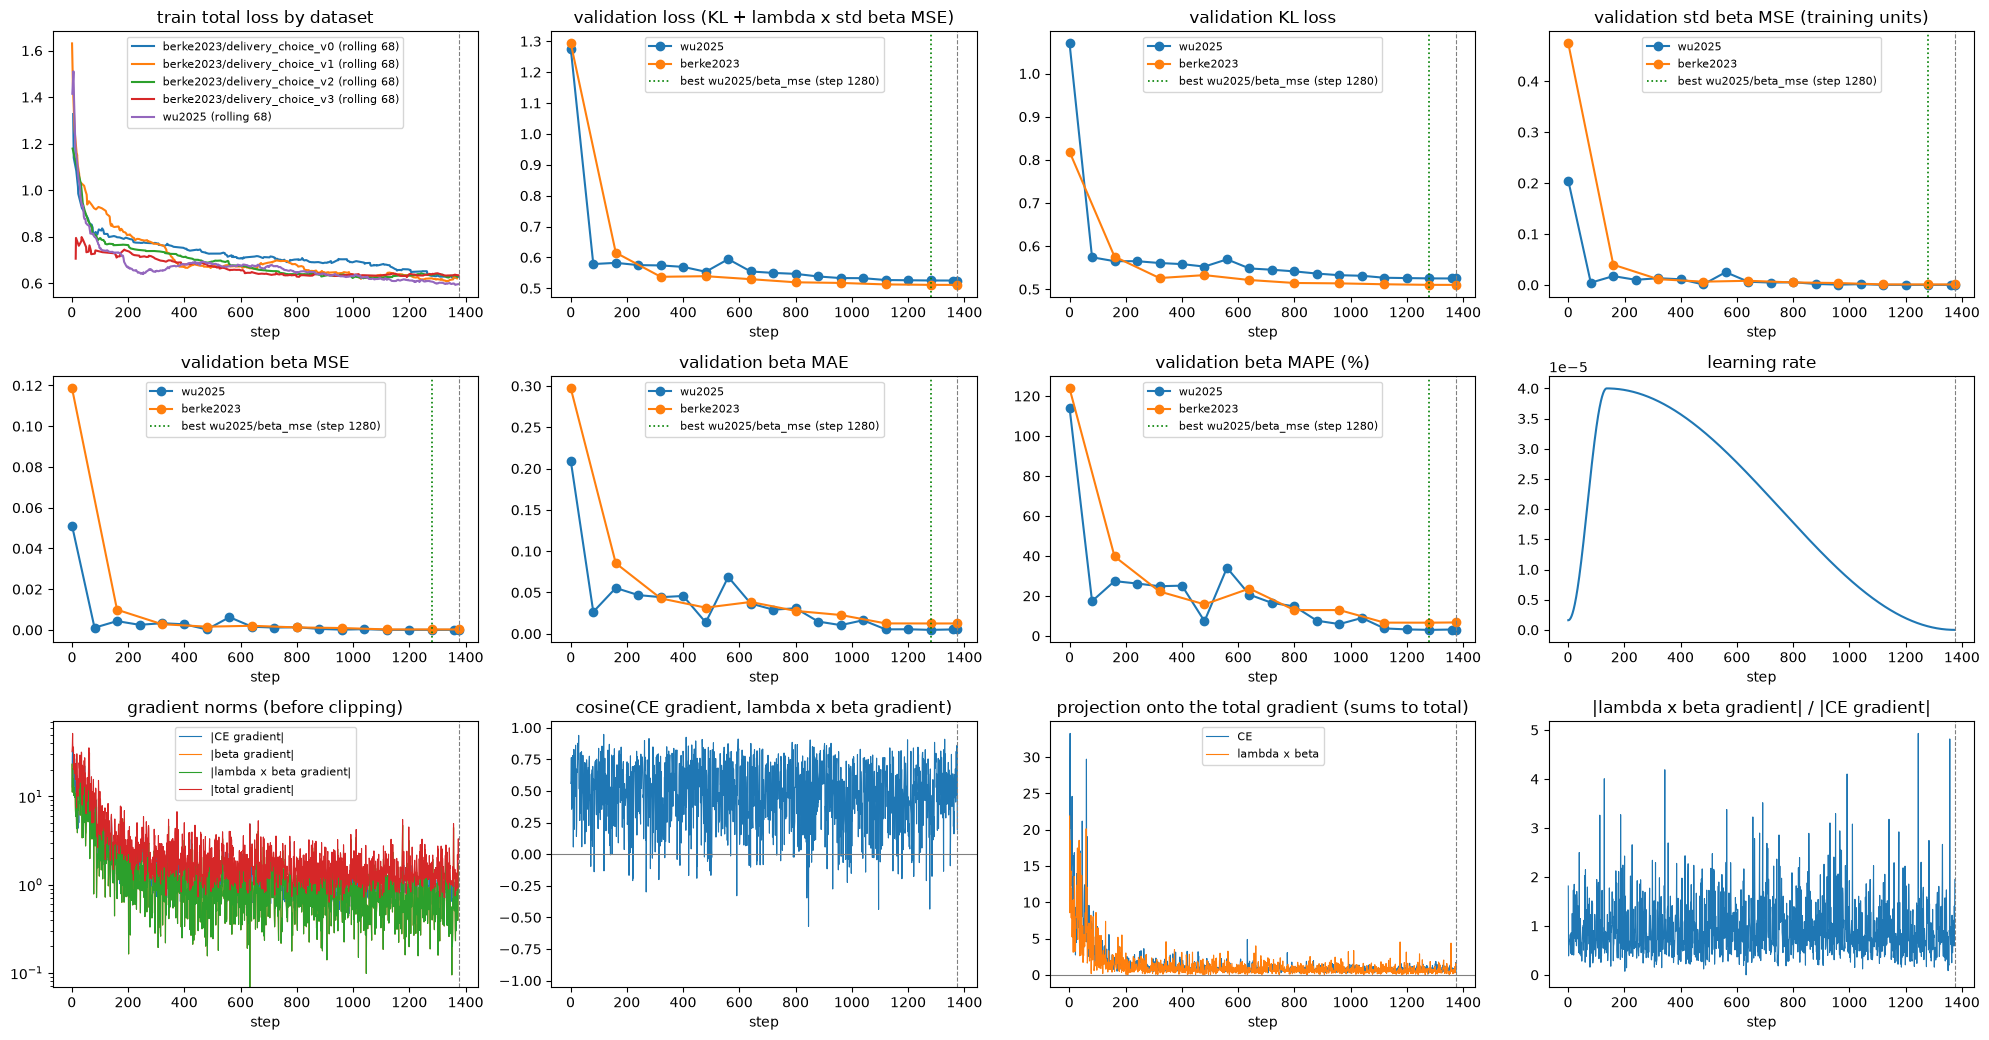

wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delive…

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 00:05:31.527752720 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 43384832, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

... (26 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 01:10:03.720566526 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 45481984, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

In [10]:
sample_size = 40
beta_lambda = 1.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,berke2023/val_loss,berke2023/std_beta_mse,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,lr,wu2025/eval_wall_sec,berke2023/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.88894,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,2.71584,0.47429,0.81868,0.11857,0.29709,123.81899,-0.34100,NaN,36.66939,138.38858,0.00000,NaN,NaN,NaN,NaN,NaN
80,1,3200,1.41954,0.61172,0.00751,0.58170,0.00188,0.03732,20.76472,0.95238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,34.93637,NaN,140.43983,12.20343,9.01233,36.04933,43.69080,0.49315
160,1,6400,1.15669,0.67706,0.02209,0.58871,0.00552,0.05882,29.20105,1.00000,0.77867,0.04228,0.60954,0.01057,0.08372,37.50009,0.89053,0.00004,35.11616,126.64155,280.25481,3.72066,3.00832,12.03330,14.18963,0.43929
240,1,9600,1.11508,0.58761,0.00430,0.57039,0.00108,0.02823,17.49809,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,34.92417,NaN,420.09215,2.00604,1.65924,6.63694,7.82159,0.44418
320,1,12800,1.09410,0.62175,0.01492,0.56207,0.00373,0.05447,28.57887,0.97619,0.53997,0.00487,0.52048,0.00122,0.02837,18.82839,0.97811,0.00004,34.95978,126.70835,556.38280,1.65415,1.32100,5.28399,6.32883,0.49297
400,1,16000,1.04361,0.59120,0.00881,0.55596,0.00220,0.04296,23.55682,1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,35.06173,NaN,699.06168,1.39867,1.25274,5.01097,5.82371,0.45021
480,1,19179,1.07759,0.55897,0.00037,0.55750,0.00009,0.00822,5.34772,1.00000,0.62887,0.01713,0.56033,0.00428,0.04985,30.20063,0.95567,0.00003,35.07250,126.66213,837.67117,1.28009,1.03431,4.13722,4.93196,0.45975
560,1,22379,1.10621,0.75372,0.04018,0.59300,0.01005,0.09079,47.39695,0.92857,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,34.92203,NaN,982.35701,1.36284,1.21896,4.87586,5.64881,0.46537
640,1,25540,1.09331,0.56967,0.00371,0.55482,0.00093,0.02740,16.09817,1.00000,0.54505,0.00632,0.51975,0.00158,0.03168,16.89950,0.98030,0.00003,34.91322,126.73700,1122.90318,1.17249,1.01513,4.06052,4.79978,0.47766


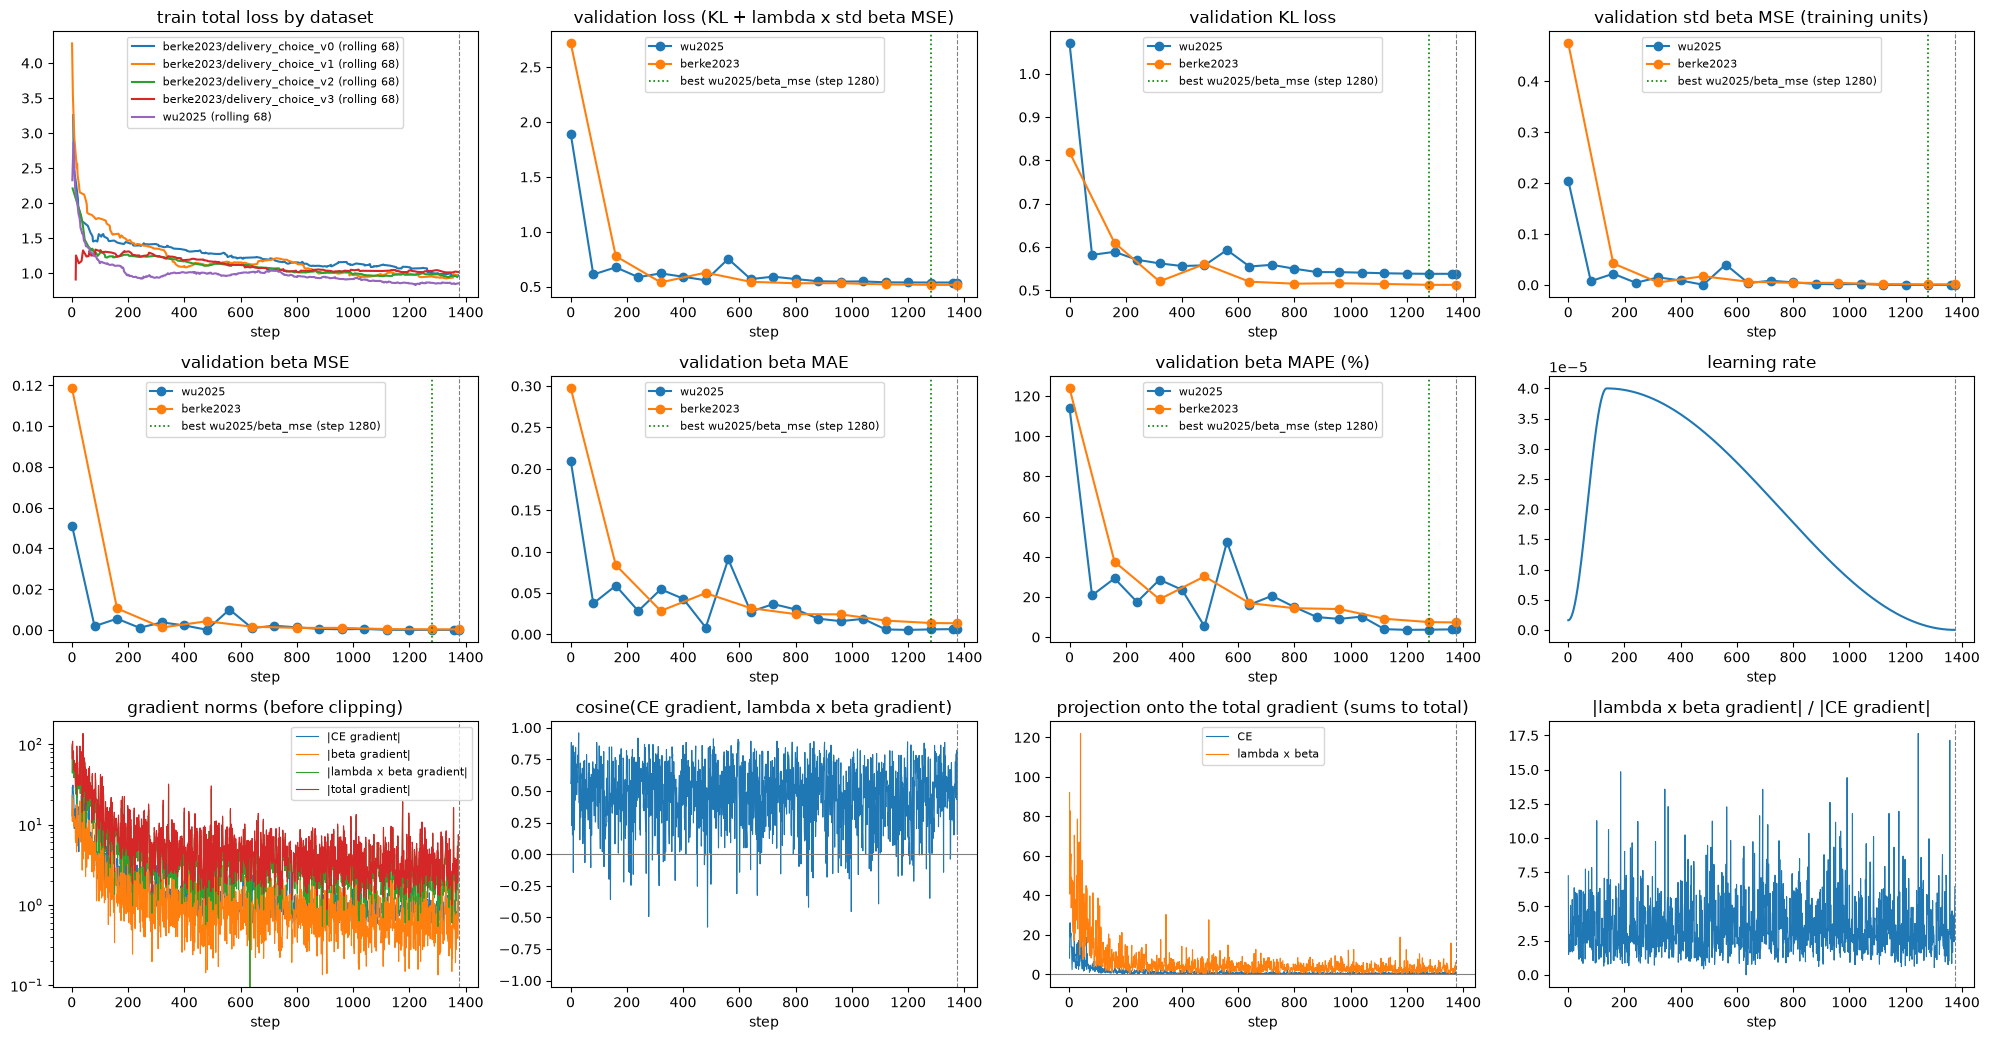

wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delive…

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 01:16:13.820997155 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 45481984, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

... (26 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 02:20:36.843734958 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 58064896, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

In [11]:
sample_size = 40
beta_lambda = 4.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,berke2023/val_loss,berke2023/std_beta_mse,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,lr,wu2025/eval_wall_sec,berke2023/eval_wall_sec,train_elapsed_sec,mean grad_ce_norm,mean grad_beta_norm,mean grad_lambda_beta_norm,mean grad_total_norm,mean grad_cos_ce_lambda_beta
step,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,4.34582,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,8.40733,0.47429,0.81868,0.11857,0.29709,123.81899,-0.34100,NaN,36.66939,138.38858,0.00000,NaN,NaN,NaN,NaN,NaN
80,1,3200,3.82850,0.70295,0.00755,0.58209,0.00189,0.03694,20.86298,0.95238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,35.00788,NaN,140.38121,16.93037,9.24373,147.89976,155.22368,0.49939
160,1,6400,3.08826,0.82116,0.01391,0.59860,0.00348,0.03060,15.80084,1.00000,1.57618,0.05794,0.64919,0.01448,0.09743,43.44601,0.88068,0.00004,34.89826,126.74029,280.18563,4.37928,3.69250,59.07997,61.48529,0.48298
240,1,9600,2.91410,0.67357,0.00646,0.57017,0.00162,0.03772,23.24073,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,35.01983,NaN,420.00513,2.39793,1.77897,28.46345,29.57520,0.42733
320,1,12800,2.63208,0.86883,0.01738,0.59069,0.00435,0.05003,28.49031,0.95238,0.71037,0.01113,0.53228,0.00278,0.04103,20.54693,0.97701,0.00004,34.98319,126.77175,556.31211,1.89445,1.33626,21.38011,22.35559,0.45349
400,1,16000,2.72557,0.86281,0.01772,0.57930,0.00443,0.05045,32.47303,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00004,35.01424,NaN,698.95341,1.79173,1.48719,23.79512,24.74323,0.47775
480,1,19179,2.81600,0.57877,0.00165,0.55234,0.00041,0.01561,7.91581,1.00000,0.89176,0.01991,0.57316,0.00498,0.05496,29.10814,0.97537,0.00003,34.96299,126.79767,837.50190,1.54159,1.16365,18.61834,19.43395,0.45585
560,1,22379,2.85807,1.00924,0.02665,0.58287,0.00666,0.07134,35.58465,0.97619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00003,35.02240,NaN,982.14897,1.39795,1.10520,17.68319,18.32942,0.41936
640,1,25540,2.68421,0.60369,0.00210,0.57014,0.00052,0.02113,13.49210,1.00000,0.60004,0.00465,0.52570,0.00116,0.02883,15.48924,0.97975,0.00003,35.00812,126.72836,1122.71101,1.42859,1.09820,17.57115,18.27024,0.41876


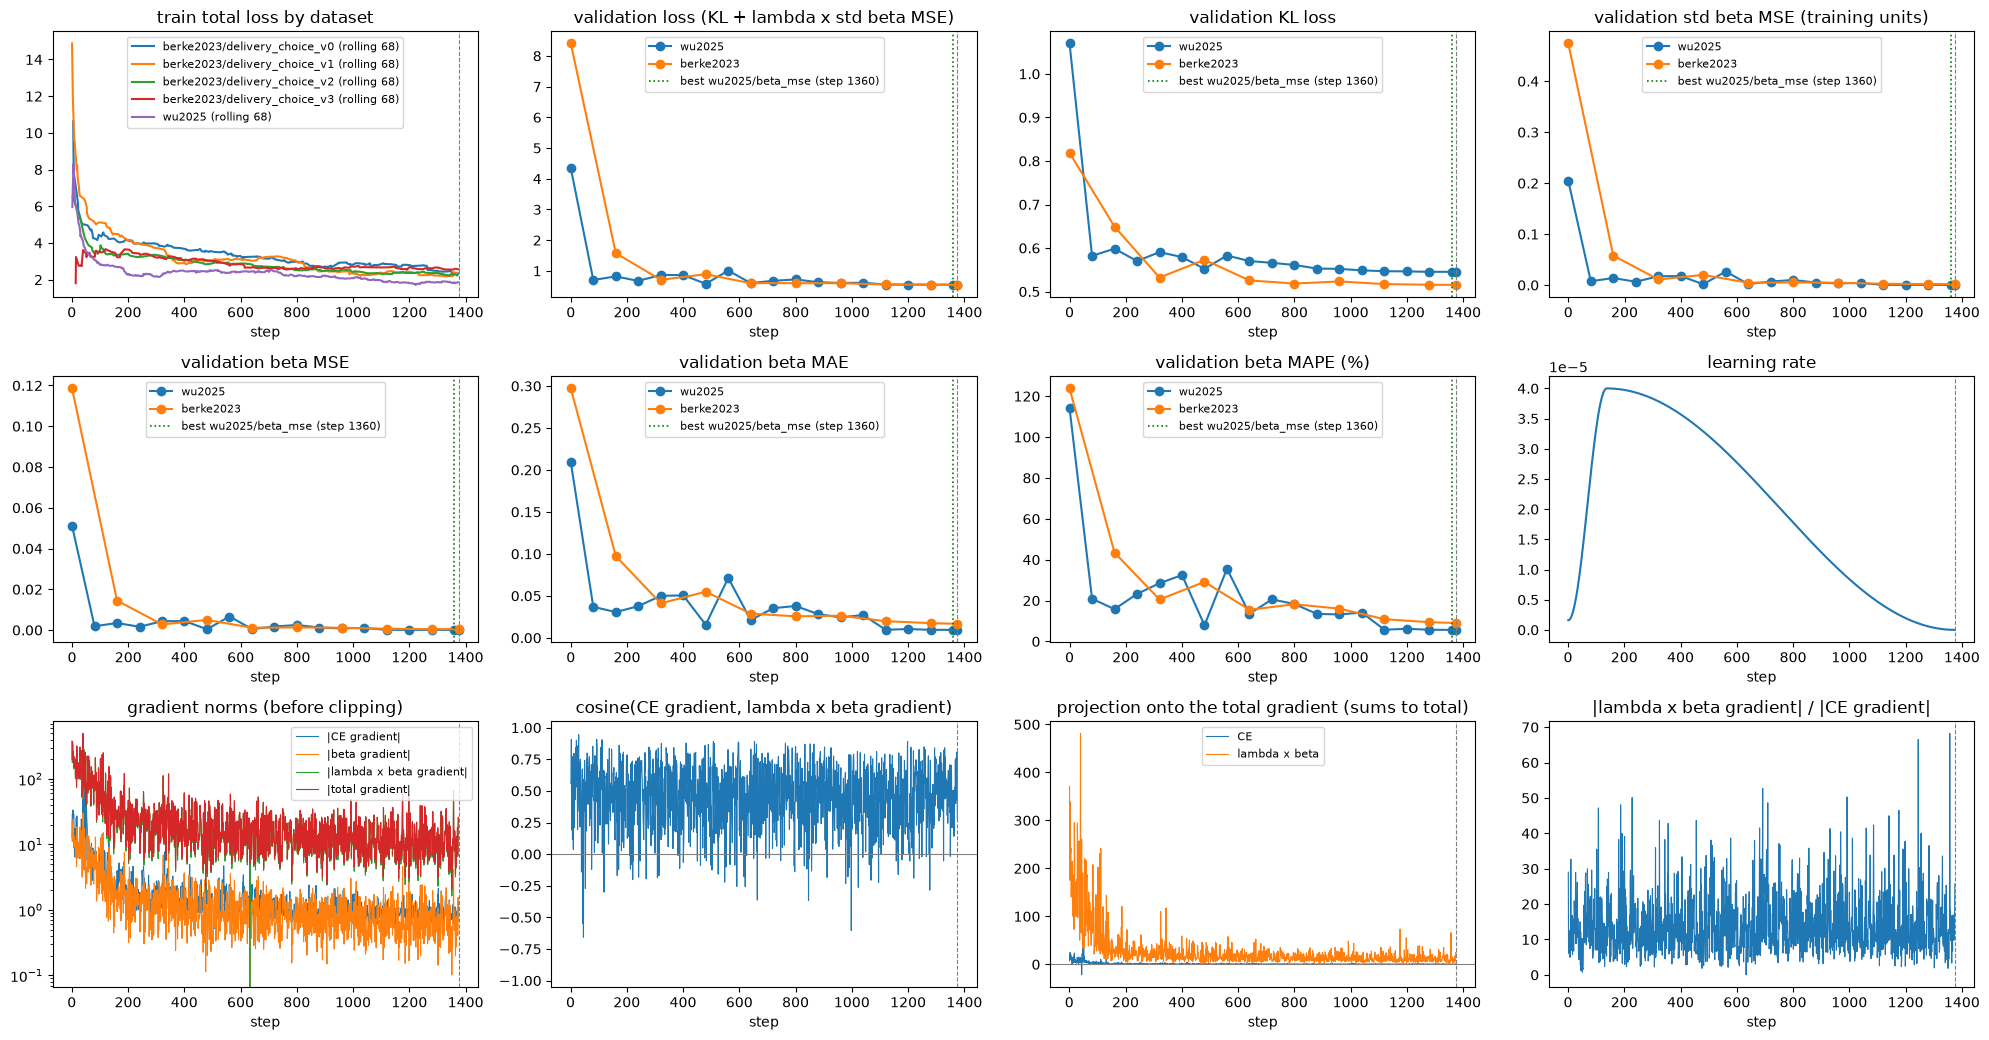

wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delive…

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

[W1117 02:26:46.668855116 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 102760448 bytes (free: 85327872, total: 33733804032).


Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

... (28 outputs left out)

Evaluating wu2025_validation (shared-state):   0%|          | 0/19 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

Evaluating berke2023_validation (shared-state):   0%|          | 0/83 [00:00<?, ?batch/s]

best.pt (step 1360) validated at the end on: berke2023


In [12]:
sample_size = 40
beta_lambda = 16.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [14]:
# Dose-response: each finished run's beta MSE on the training datasets (whole data), by beta_lambda
# (step 0 = untrained; lowest = best validation in the epoch; last = end of the epoch)
dose_rows = []
for saved_run_dir in sorted(RUNS_DIR.iterdir()):
    run_info = json.loads((saved_run_dir / "run.json").read_text())
    if run_info["status"] != "finished":
        print(f"skipped (status {run_info['status']}): {saved_run_dir.name}")
        continue
    val_history = pd.read_csv(saved_run_dir / "val_history.csv")
    for validator_name in VALIDATION_DATASETS:
        validator_rows = val_history.dropna(subset=[f"{validator_name}/beta_mse"])
        beta_mse = validator_rows[f"{validator_name}/beta_mse"]
        dose_rows.append({
            "validator": validator_name,
            "beta_lambda": run_info["identity"]["config"]["beta_lambda"],
            "step0_beta_mse": beta_mse.iloc[0],
            "lowest_beta_mse": beta_mse.min(),
            "last_beta_mse": beta_mse.iloc[-1],
            "last_kl_loss": validator_rows[f"{validator_name}/kl_loss"].iloc[-1],
        })
dose_df = pd.DataFrame(dose_rows).sort_values(["validator", "beta_lambda"])
display(dose_df.set_index(["validator", "beta_lambda"]).round(5))

step0_beta_mse  lowest_beta_mse  last_beta_mse  last_kl_loss
validator beta_lambda                                                              
berke2023 0.0                 0.11857          0.00037        0.00037       0.50630
          1.0                 0.11857          0.00025        0.00025       0.51006
          4.0                 0.11857          0.00030        0.00030       0.51243
          16.0                0.11857          0.00046        0.00046       0.51549
wu2025    0.0                 0.05118          0.00003        0.00004       0.49443
          1.0                 0.05118          0.00004        0.00005       0.52487
          4.0                 0.05118          0.00005        0.00005       0.53794
          16.0                0.05118          0.00011        0.00011       0.54546

In [15]:
# Compare finished runs: final validation metrics, per-dataset train losses, and each validator's betas
display(comparison_table(runs, step0_validation).round(5))
display(per_dataset_table(runs).round(5))
for dataset_name in validators:
    display(eval_beta_table(runs, step0_validation, dataset_name).round(4))

# The same runs at their best validation (by each run's best metric)
display(best_table(runs).round(5))
for dataset_name in validators:
    display(best_beta_table(runs, step0_validation, dataset_name).round(4))

,train_datasets,beta_lambda,num_epochs,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,steps_per_epoch,mean_step_ms,train_only_sec,eval_only_sec,total_wall_sec
run,,,,,,,,,,,,,,,,,,
step_0 (untrained),,NaN,0,1.06998,0.05118,0.20927,114.14264,-0.21429,0.81868,0.11857,0.29709,123.81899,-0.34100,NaN,NaN,NaN,NaN,NaN
lambda=1_lr=4e-05_S=40_ep=1,wu2025+berke2023/delivery_choice_v0+berke2023/...,1.0,1,0.52487,0.00005,0.00526,3.15418,0.97619,0.51006,0.00025,0.01247,6.70734,0.99343,1375.0,1768.74303,2432.02167,1776.63209,4244.77645
lambda=4_lr=4e-05_S=40_ep=1,wu2025+berke2023/delivery_choice_v0+berke2023/...,4.0,1,0.53794,0.00005,0.00631,3.82123,0.97619,0.51243,0.00030,0.01340,7.27955,0.99234,1375.0,1765.49707,2427.55847,1769.49148,4232.76138
lambda=16_lr=4e-05_S=40_ep=1,wu2025+berke2023/delivery_choice_v0+berke2023/...,16.0,1,0.54546,0.00011,0.00946,5.66147,0.97619,0.51549,0.00046,0.01667,9.01856,0.99179,1375.0,1765.44732,2427.49007,1896.91499,4363.12156
lambda=0_lr=4e-05_S=40_ep=1,wu2025+berke2023/delivery_choice_v0+berke2023/...,0.0,1,0.49443,0.00004,0.00556,3.75227,0.97619,0.50630,0.00037,0.01454,8.69973,0.98741,1375.0,1765.60353,2427.70486,1770.17606,4232.48215


sample_size  steps  steps_without_beta  skipped_groups_total  train_kl_first15pct  \
run                          dataset                                                                                                           
lambda=1_lr=4e-05_S=40_ep=1  wu2025                                 40    465                   0                     0              0.59798   
                             berke2023/delivery_choice_v0           40    239                   0                     0              0.57670   
                             berke2023/delivery_choice_v1           40    288                   1                     1              0.60593   
                             berke2023/delivery_choice_v2           40    182                   0                     0              0.58941   
                             berke2023/delivery_choice_v3           40    201                   0                     0              0.55167   
lambda=4_lr=4e-05_S=40_ep=1  wu2025                                 40    465                   0                     0              0.60872   
                             berke2023/delivery_choice_v0           40    239                   0                     0              0.59910   
                             berke2023/delivery_choice_v1           40    288                   1                     1              0.62089   
                             berke2023/delivery_choice_v2           40    182                   0                     0              0.59568   
                             berke2023/delivery_choice_v3           40    201                   0                     0              0.55467   
lambda=16_lr=4e-05_S=40_ep=1 wu2025                                 40    465                   0                     0              0.63117   
                             berke2023/delivery_choice_v0           40    239                   0                     0              0.61903   
                             berke2023/delivery_choice_v1           40    288                   1                     1              0.68005   
                             berke2023/delivery_choice_v2           40    182                   0                     0              0.63602   
                             berke2023/delivery_choice_v3           40    201                   0                     0              0.59906   
lambda=0_lr=4e-05_S=40_ep=1  wu2025                                 40    465                   0                     0              0.60815   
                             berke2023/delivery_choice_v0           40    239                   0                     0              0.57621   
                             berke2023/delivery_choice_v1           40    288                   1                     1              0.58960   
                             berke2023/delivery_choice_v2           40    182                   0                     0              0.60032   
                             berke2023/delivery_choice_v3           40    201                   0                     0              0.54835   

                                                           train_kl_last15pct  train_raw_beta_first15pct  train_raw_beta_last15pct  
run                          dataset                                                                                                
lambda=1_lr=4e-05_S=40_ep=1  wu2025                                   0.51551                    0.11752                   0.07760  
                             berke2023/delivery_choice_v0             0.52367                    0.19691                   0.11364  
                             berke2023/delivery_choice_v1             0.50431                    0.20750                   0.10506  
                             berke2023/delivery_choice_v2             0.52431                    0.15989                   0.08343  
                             berke2023/delivery_choice_v3             0.50812               

,human_pop_beta,step_0,lambda=1_lr=4e-05_S=40_ep=1,lambda=4_lr=4e-05_S=40_ep=1,lambda=16_lr=4e-05_S=40_ep=1,lambda=0_lr=4e-05_S=40_ep=1
term,,,,,,
Monthly bill: $110 vs $105,-0.0969,-0.0068,-0.0971,-0.1019,-0.1045,-0.0941
Monthly bill: $115 vs $105,-0.1779,-0.0121,-0.1744,-0.1795,-0.1889,-0.1733
Monthly bill: $120 vs $105,-0.2894,-0.0171,-0.2934,-0.2976,-0.3014,-0.2882
Monthly bill: $125 vs $105,-0.3832,-0.0247,-0.3851,-0.3917,-0.3925,-0.3849
Percentage of renewables: 30% vs 10%,0.0973,-0.0075,0.0995,0.0992,0.1011,0.1034
Percentage of renewables: 50% vs 10%,0.1706,-0.0150,0.1843,0.1811,0.1890,0.1801
Percentage of renewables: 100% vs 10%,0.2421,-0.0399,0.2512,0.2472,0.2364,0.2531
Locally produced renewables: Yes vs No,0.1042,-0.1109,0.0969,0.0946,0.0962,0.0967


,human_pop_beta,step_0,lambda=1_lr=4e-05_S=40_ep=1,lambda=4_lr=4e-05_S=40_ep=1,lambda=16_lr=4e-05_S=40_ep=1,lambda=0_lr=4e-05_S=40_ep=1
term,,,,,,
v0: take-out food | Drone privacy: YES vs NO,0.1607,-0.2362,0.1849,0.1835,0.1878,0.1796
v0: take-out food | Fee L1 vs $0 ($1),-0.1509,-0.0218,-0.1537,-0.1515,-0.1546,-0.1482
v0: take-out food | Fee L2 vs $0 ($3 fast / $5 meds),-0.3298,-0.0141,-0.3466,-0.3469,-0.3460,-0.3283
v0: take-out food | Fee L3 vs $0 ($5 fast / $10 meds),-0.4978,0.0002,-0.4904,-0.4889,-0.4870,-0.4739
v0: take-out food | Wait L1 vs L0 (20m fast / 2h meds),-0.0631,0.0024,-0.0532,-0.0503,-0.0467,-0.0509
v0: take-out food | Wait L2 vs L0 (30m fast / 6h meds),-0.2082,0.0211,-0.1891,-0.1865,-0.1887,-0.1774
v0: take-out food | Wait L3 vs L0 (45m fast / 1d meds),-0.3419,0.0371,-0.3055,-0.3026,-0.2866,-0.2852
v1: prescription medications | Drone privacy: YES vs NO,0.2242,-0.3136,0.2087,0.2099,0.2069,0.2002
v1: prescription medications | Fee L1 vs $0 ($1),-0.0822,-0.0243,-0.1015,-0.1101,-0.1181,-0.1093


,beta_lambda,best_metric,best_mode,best_step,best_value,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,...,berke2023/std_beta_mse,berke2023/kl_loss,berke2023/beta_mse,berke2023/beta_mae,berke2023/beta_mape_pct,berke2023/spearman_rho,lr,wu2025/eval_wall_sec,berke2023/eval_wall_sec,train_elapsed_sec
run,,,,,,,,,,,,,,,,,,,,,
lambda=1_lr=4e-05_S=40_ep=1,1.0,wu2025/beta_mse,min,1280,0.00004,1,51097,0.60922,0.52526,0.00016,...,0.00101,0.51007,0.00025,0.01247,6.59085,0.99343,0.0,34.98825,126.63178,2263.97529
lambda=4_lr=4e-05_S=40_ep=1,4.0,wu2025/beta_mse,min,1280,0.00005,1,51097,0.90343,0.53868,0.00019,...,0.00124,0.51248,0.00031,0.01371,7.46197,0.99234,0.0,35.04851,126.63547,2259.51249
lambda=16_lr=4e-05_S=40_ep=1,16.0,wu2025/beta_mse,min,1360,0.00011,1,54288,2.15492,0.55228,0.00043,...,0.00185,0.51550,0.00046,0.01668,9.03394,0.99179,0.0,35.07578,126.69162,2400.24724
lambda=0_lr=4e-05_S=40_ep=1,0.0,wu2025/beta_mse,min,1280,0.00003,1,51097,0.50899,0.49465,0.00013,...,0.00149,0.50654,0.00037,0.01467,8.59001,0.98796,0.0,34.87210,126.84051,2259.63049


,human_pop_beta,step_0,lambda=1_lr=4e-05_S=40_ep=1 (best step 1280),lambda=4_lr=4e-05_S=40_ep=1 (best step 1280),lambda=16_lr=4e-05_S=40_ep=1 (best step 1360),lambda=0_lr=4e-05_S=40_ep=1 (best step 1280)
term,,,,,,
Monthly bill: $110 vs $105,-0.0969,-0.0068,-0.0966,-0.1016,-0.1046,-0.0926
Monthly bill: $115 vs $105,-0.1779,-0.0121,-0.1734,-0.1790,-0.1889,-0.1705
Monthly bill: $120 vs $105,-0.2894,-0.0171,-0.2919,-0.2968,-0.3013,-0.2839
Monthly bill: $125 vs $105,-0.3832,-0.0247,-0.3831,-0.3908,-0.3925,-0.3793
Percentage of renewables: 30% vs 10%,0.0973,-0.0075,0.0991,0.0991,0.1011,0.1011
Percentage of renewables: 50% vs 10%,0.1706,-0.0150,0.1835,0.1810,0.1890,0.1761
Percentage of renewables: 100% vs 10%,0.2421,-0.0399,0.2498,0.2467,0.2364,0.2471
Locally produced renewables: Yes vs No,0.1042,-0.1109,0.0962,0.0941,0.0962,0.0954


,human_pop_beta,step_0,lambda=1_lr=4e-05_S=40_ep=1 (best step 1280),lambda=4_lr=4e-05_S=40_ep=1 (best step 1280),lambda=16_lr=4e-05_S=40_ep=1 (best step 1360),lambda=0_lr=4e-05_S=40_ep=1 (best step 1280)
term,,,,,,
v0: take-out food | Drone privacy: YES vs NO,0.1607,-0.2362,0.1849,0.1831,0.1878,0.1789
v0: take-out food | Fee L1 vs $0 ($1),-0.1509,-0.0218,-0.1539,-0.1519,-0.1546,-0.1467
v0: take-out food | Fee L2 vs $0 ($3 fast / $5 meds),-0.3298,-0.0141,-0.3473,-0.3480,-0.3461,-0.3262
v0: take-out food | Fee L3 vs $0 ($5 fast / $10 meds),-0.4978,0.0002,-0.4911,-0.4898,-0.4870,-0.4705
v0: take-out food | Wait L1 vs L0 (20m fast / 2h meds),-0.0631,0.0024,-0.0535,-0.0508,-0.0467,-0.0511
v0: take-out food | Wait L2 vs L0 (30m fast / 6h meds),-0.2082,0.0211,-0.1896,-0.1872,-0.1886,-0.1776
v0: take-out food | Wait L3 vs L0 (45m fast / 1d meds),-0.3419,0.0371,-0.3057,-0.3029,-0.2866,-0.2852
v1: prescription medications | Drone privacy: YES vs NO,0.2242,-0.3136,0.2079,0.2089,0.2069,0.1988
v1: prescription medications | Fee L1 vs $0 ($1),-0.0822,-0.0243,-0.1016,-0.1104,-0.1182,-0.1081


In [16]:
# Load every saved run of this notebook from disk (no training; works in a fresh kernel after the setup cells)
runs = {}
for saved_run_dir in sorted(RUNS_DIR.iterdir()):
    runs[saved_run_dir.name] = load_run(saved_run_dir)
display(pd.DataFrame([run.summary for run in runs.values()]).set_index("label"))

,steps_per_epoch,total_steps,rows_seen,best_metric,best_mode,best_step,best_value,mean_grad_norm,mean_step_ms,mean_ms_per_row,mean_eval_wall_sec,train_only_sec,eval_only_sec,total_wall_sec
label,,,,,,,,,,,,,,
wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | lambda=0,1375,1375,54888,wu2025/beta_mse,min,1280,0.000033,1.791457,1765.603534,44.230157,98.343114,2427.704859,1770.176061,4232.482154
wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | lambda=16,1375,1375,54888,wu2025/beta_mse,min,1360,0.000107,27.808182,1765.447322,44.226244,98.345743,2427.490067,1896.914987,4363.121557
wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | lambda=1,1375,1375,54888,wu2025/beta_mse,min,1280,0.000040,2.916662,1768.743032,44.308805,98.701783,2432.021669,1776.632092,4244.776451
wu2025+berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choice_v3 | lambda=4,1375,1375,54888,wu2025/beta_mse,min,1280,0.000046,7.460224,1765.497072,44.227490,98.305082,2427.558474,1769.491476,4232.761383


In [17]:
# Put one run's best checkpoint into kev_model (e.g. to evaluate it further)
BEST_RUN_DIR = RUNS_DIR / run_name(make_run_config(BASE_SAMPLE_SIZE, BETA_LAMBDA))
best_checkpoint = load_best(BEST_RUN_DIR)
reset_trainable(kev_model, best_checkpoint["trainable"])
display(pd.Series(best_checkpoint["best"], name=BEST_RUN_DIR.name).to_frame())

,lambda=1_lr=4e-05_S=40_ep=1
metric,wu2025/beta_mse
mode,min
step,1280
value,0.00004


In [18]:
# Decompose each validator's beta MSE into per-beta squared errors across runs
for dataset_name in validators:
    display(mse_decomposition(runs, step0_validation, dataset_name).round(5))

,human_beta,pred | lambda=0_lr=4e-05_S=40_ep=1,pred | lambda=16_lr=4e-05_S=40_ep=1,pred | lambda=1_lr=4e-05_S=40_ep=1,pred | lambda=4_lr=4e-05_S=40_ep=1,sq_err | lambda=0_lr=4e-05_S=40_ep=1,sq_err | lambda=16_lr=4e-05_S=40_ep=1,sq_err | lambda=1_lr=4e-05_S=40_ep=1,sq_err | lambda=4_lr=4e-05_S=40_ep=1
Monthly bill: $110 vs $105,-0.09691,-0.09409,-0.10454,-0.09710,-0.10188,0.00001,0.00006,0.00000,0.00002
Monthly bill: $115 vs $105,-0.17794,-0.17330,-0.18888,-0.17438,-0.17950,0.00002,0.00012,0.00001,0.00000
Monthly bill: $120 vs $105,-0.28943,-0.28820,-0.30137,-0.29342,-0.29764,0.00000,0.00014,0.00002,0.00007
Monthly bill: $125 vs $105,-0.38318,-0.38491,-0.39250,-0.38513,-0.39174,0.00000,0.00009,0.00000,0.00007
Percentage of renewables: 30% vs 10%,0.09728,0.10342,0.10108,0.09955,0.09920,0.00004,0.00001,0.00001,0.00000
Percentage of renewables: 50% vs 10%,0.17063,0.18006,0.18899,0.18431,0.18108,0.00009,0.00034,0.00019,0.00011
Percentage of renewables: 100% vs 10%,0.24212,0.25306,0.23642,0.25117,0.24722,0.00012,0.00003,0.00008,0.00003
Locally produced renewables: Yes vs No,0.10423,0.09666,0.09622,0.09688,0.09456,0.00006,0.00006,0.00005,0.00009
MEAN (= beta_mse on sq_err columns),-0.04165,-0.03841,-0.04557,-0.03976,-0.04359,0.00004,0.00011,0.00005,0.00005


,human_beta,pred | lambda=0_lr=4e-05_S=40_ep=1,pred | lambda=16_lr=4e-05_S=40_ep=1,pred | lambda=1_lr=4e-05_S=40_ep=1,pred | lambda=4_lr=4e-05_S=40_ep=1,sq_err | lambda=0_lr=4e-05_S=40_ep=1,sq_err | lambda=16_lr=4e-05_S=40_ep=1,sq_err | lambda=1_lr=4e-05_S=40_ep=1,sq_err | lambda=4_lr=4e-05_S=40_ep=1
v0: take-out food | Drone privacy: YES vs NO,0.16068,0.17961,0.18784,0.18495,0.18354,0.00036,0.00074,0.00059,0.00052
v0: take-out food | Fee L1 vs $0 ($1),-0.15091,-0.14823,-0.15458,-0.15367,-0.15153,0.00001,0.00001,0.00001,0.00000
v0: take-out food | Fee L2 vs $0 ($3 fast / $5 meds),-0.32976,-0.32826,-0.34604,-0.34656,-0.34695,0.00000,0.00026,0.00028,0.00030
v0: take-out food | Fee L3 vs $0 ($5 fast / $10 meds),-0.49782,-0.47387,-0.48695,-0.49036,-0.48886,0.00057,0.00012,0.00006,0.00008
v0: take-out food | Wait L1 vs L0 (20m fast / 2h meds),-0.06306,-0.05088,-0.04673,-0.05318,-0.05035,0.00015,0.00027,0.00010,0.00016
v0: take-out food | Wait L2 vs L0 (30m fast / 6h meds),-0.20819,-0.17736,-0.18865,-0.18914,-0.18647,0.00095,0.00038,0.00036,0.00047
v0: take-out food | Wait L3 vs L0 (45m fast / 1d meds),-0.34187,-0.28516,-0.28657,-0.30555,-0.30265,0.00322,0.00306,0.00132,0.00154
v1: prescription medications | Drone privacy: YES vs NO,0.22422,0.20020,0.20692,0.20867,0.20986,0.00058,0.00030,0.00024,0.00021
v1: prescription medications | Fee L1 vs $0 ($1),-0.08221,-0.10934,-0.11808,-0.10148,-0.11011,0.00074,0.00129,0.00037,0.00078
v1: prescription medications | Fee L2 vs $0 ($3 fast / $5 meds),-0.29643,-0.34113,-0.34121,-0.33562,-0.33170,0.00200,0.00200,0.00154,0.00124


# Cross-dataset beta scale and sample-size target noise

In [ ]:
# Compare raw vs sigma_y-standardized human beta mean-square across the loaded datasets
scale_rows = []
for dataset_name, tidy in human_ols_by_dataset.items():
    choice_df = choice_dfs[dataset_name]
    option_counts = sorted({len(one_hot) for one_hot in choice_df["one_hot"]})
    sigma_by_model = tidy.groupby("model", sort=False)["sigma_y"].first()
    scale_rows.append(
        {
            "dataset": dataset_name,
            "respondents": choice_df["CASEID"].nunique(),
            "tasks": len(choice_df),
            "options_per_task": ", ".join(str(n) for n in option_counts),
            "regressions": len(sigma_by_model),
            "num_betas": len(tidy),
            "sigma_y": ", ".join(f"{sigma:.4g}" for sigma in sigma_by_model),
            "raw_signal_beta_ms": float((tidy["human_beta"] ** 2).mean()),
            "std_signal_beta_ms": float((tidy["std_beta"] ** 2).mean()),
        }
    )
display(pd.DataFrame(scale_rows).set_index("dataset").round(5))

# Rank deficiency

In [ ]:
# Target noise of sample betas vs row sample size (Monte Carlo over data rows = training items), per regression
for SNR_DATASET in TRAIN_DATASETS:  
    SNR_SAMPLE_SIZES = [16, 32, 64, 128, 256]
    SNR_DRAWS = 4000

    beta_noise_df = beta_core.beta_noise_by_sample_size(
        regression_rows_by_dataset[SNR_DATASET],
        regression_specs_by_dataset[SNR_DATASET],
        SNR_SAMPLE_SIZES,
        SNR_DRAWS,
        seed=42,
    )
    display(beta_noise_df.set_index(["model", "sample_size"]).round(4))

# Test micro-batching

In [ ]:
# Two-pass micro-chunked gradient (training) vs one backward through the whole sample
CHECK_DATASET = "wu2025"   # any key of `unified_items`
CHECK_SAMPLE_SIZE = 15          # one graph of this many items (rows) must fit in VRAM (method A)
CHECK_MICRO_CHUNK = 3           # items (data rows) per chunk
CHECK_BETA_LAMBDA = 5.0         # > 0 so both KL and beta gradients are tested

gradient_check_result = gradient_check(
    kev_model,
    unified_items[CHECK_DATASET],
    regression_specs_by_dataset[CHECK_DATASET],
    INIT_TRAINABLE_STATE,
    sample_size=CHECK_SAMPLE_SIZE,
    micro_chunk=CHECK_MICRO_CHUNK,
    beta_lambda=CHECK_BETA_LAMBDA,
    seed=0,
    device=device,
)
display(pd.Series(gradient_check_result, name="gradient_check").to_frame())

# Overfit first

In [ ]:
# Overfit sanity check: many passes with pure KL/CE, constant LR, and zero weight decay
BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)

OVERFIT_CONFIG = TrainConfig(
    train_datasets=("wu2025",),
    sample_size_by_dataset={"wu2025": 128},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_SAMPLE_1, 128),
    num_epochs=10,
    eval_every_by_validator={name: math.ceil(len(unified_items["wu2025"]) / 128) for name in VALIDATION_DATASETS},   # one validation per epoch
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
overfit_run = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=OVERFIT_CONFIG,
    device=device,
    run_dir=RUNS_DIR / f"overfit_{run_name(OVERFIT_CONFIG)}",
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)